In [1]:
from bccr import SW 
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [7]:
#se cargan los datos para el análisis
def cargar_datos():
    df_minidevaluaciones = pd.read_csv(
        "../src/raw_data/modeloMinidevaluaciones.csv",
        index_col=0,      # usa la primera columna (las fechas) como índice
        parse_dates=True  # la convierte a formato fecha, no texto
    )

    df_bandas = pd.read_csv(
        "../src/raw_data/modeloBandas.csv",
        index_col=0,      # usa la primera columna (las fechas) como índice
        parse_dates=True  # la convierte a formato fecha, no texto
    )

    df_flotacion = pd.read_csv(
        "../src/raw_data/modeloFlotacion.csv",
        index_col=0,      # usa la primera columna (las fechas) como índice
        parse_dates=True  # la convierte a formato fecha, no texto
    )

    df_ipc = pd.read_csv(
        "../src/raw_data/ipc.csv",
        index_col=0,      # usa la primera columna (las fechas) como índice
        parse_dates=True  # la convierte a formato fecha, no texto
    )

    return (
        df_minidevaluaciones,
        df_bandas,
        df_flotacion,
        df_ipc
    )

In [8]:
df_minidevaluaciones, df_bandas, df_flotacion, df_ipc = cargar_datos()

### Limpieza de datos

In [9]:
df = df_flotacion.copy()

In [10]:
df.shape

(4268, 2)

In [12]:
df.index.min()

Timestamp('2015-01-30 00:00:00')

In [13]:
df.index.max()

Timestamp('2026-10-06 00:00:00')

In [15]:
df.index.is_monotonic_increasing

True

In [17]:
repeated=df['venta'].diff() == 0

In [18]:
print(repeated.sum(), "de", len(df))

1379 de 4268


In [19]:
df[repeated].index.dayofweek.value_counts().sort_index()

0    610
1     43
2     20
3     21
4     32
5     43
6    610
Name: count, dtype: int64

In [27]:
df = df[df.index.dayofweek < 5] #De lunes a viernes

In [28]:
repeated=df['venta'].diff() == 0
repeated

2015-01-30    False
2015-02-02    False
2015-02-03    False
2015-02-04    False
2015-02-05    False
              ...  
2026-09-30    False
2026-10-01    False
2026-10-02    False
2026-10-05    False
2026-10-06    False
Name: venta, Length: 3048, dtype: bool

In [29]:
df[repeated].index.dayofweek.value_counts().sort_index()

0    43
1    43
2    20
3    21
4    32
Name: count, dtype: int64

In [36]:
df.head()

,compra,venta
2015-01-30,530.53,542.64
2015-02-02,530.85,543.08
2015-02-03,530.98,543.16
2015-02-04,530.85,543.09
2015-02-05,531.58,543.75


In [48]:
import pandas as pd

# 1. Asegurar que el índice de tu DataFrame sea de tipo DatetimeIndex
df.index = pd.to_datetime(df.index)

# 2. Definir los feriados fijos de Costa Rica (MM-DD)
feriados_fijos = [
    '01-01',  # Año Nuevo
    '04-11',  # Día de Juan Santamaría
    '05-01',  # Día del Trabajo
    '07-25',  # Anexión del Partido de Nicoya
    '08-02',  # Día de la Virgen de los Ángeles
    '08-15',  # Día de la Madre
    '08-31',  # Día de la Persona Negra
    '09-15',  # Día de la Independencia
    '12-01',  # Día de la Abolición del Ejército
    '12-25'   # Navidad
]

# 3. Lista de Jueves y Viernes Santo (2015 - 2026)
semana_santa_lista = [
    '2015-04-02', '2015-04-03', '2016-03-24', '2016-03-25',
    '2017-04-13', '2017-04-14', '2018-03-29', '2018-03-30',
    '2019-04-18', '2019-04-19', '2020-04-09', '2020-04-10',
    '2021-04-01', '2021-04-02', '2022-04-14', '2022-04-15',
    '2023-04-06', '2023-04-07', '2024-03-28', '2024-03-29',
    '2025-04-17', '2025-04-18', '2026-04-02', '2026-04-03'
]
semana_santa_dt = pd.to_datetime(semana_santa_lista)

# 4. Crear las condiciones de filtrado usando el ÍNDICE (df.index)
condicion_fijos = df.index.strftime('%m-%d').isin(feriados_fijos)
condicion_variables = df.index.isin(semana_santa_dt)

# Máscara final combinada
es_feriado = condicion_fijos | condicion_variables

# =====================================================================
# FILTRADO FINAL
# =====================================================================

# OPCIÓN A: Eliminar los feriados (Quedarse solo con días transaccionales limpios)
df_limpio = df[~es_feriado]

# OPCIÓN B: Ver qué registros de tu DataFrame original cayeron en día feriado
df_solo_feriados = df[es_feriado]

In [49]:
df_clean = df_limpio.dropna()

In [50]:
df_clean.head()

,compra,venta,ret
2015-02-02,530.85,543.08,0.000811
2015-02-03,530.98,543.16,0.000147
2015-02-04,530.85,543.09,-0.000129
2015-02-05,531.58,543.75,0.001215
2015-02-06,532.48,544.64,0.001635


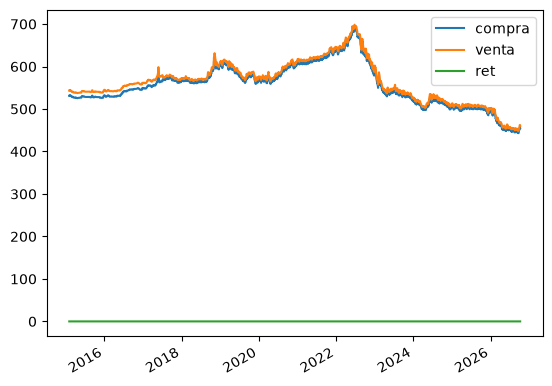

In [52]:
df_clean.plot();